<!-- # Setup -->

# Pineapple Yield Prediction

Pineapple yield (mt/ha) at province-semester level for the Philippines, with a SOCCSKSARGEN focus. Intended users: DA Regional Field Office XII and NEDA/DEPDev Region 12, for early warning and investment targeting.

Target is `log1p(yield)`; metric is RMSE. Evaluation is time-based: train <= 2022, validate 2023-24, test >= 2025, so no future information leaks into training. 

Models used: `regression`, `decision tree`, `random forest`, and `xgboost`.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from tqdm.auto import tqdm

import xgboost as xgb

%matplotlib inline


In [2]:
# Load Data

psa_area_data = pd.read_csv('data/normalized/psa_area_long.csv')
psa_prod_data = pd.read_csv('data/normalized/psa_production_long.csv')
# psa_farmgate = pd.read_csv('data/normalized/psa_farmgate_long.csv') # use only for valuation
# psa_ppa      = pd.read_csv('data/normalized/psa_ppa_long.csv')      # use only for context
noaa_enso_data    = pd.read_csv('data/normalized/noaa_enso_long.csv')
nasa_weather_data = pd.read_csv('data/normalized/nasa_weather_long.csv')

<!-- # Data Preparation

For data inclusion/exclusion â€” see docs/data_dictionary.md -->

## Preparation

### PSA

In [3]:
# area and prod have the same schema

area_prod_cols = ['crop', 'geo_level_name', 'region_name', 'province_name', 'year', 'period_type', 'period', 'value']

<!-- ## PSA -->

In [4]:
# trim columns, merge PSA data, rename and format

psa_area = psa_area_data[area_prod_cols]
psa_prod = psa_prod_data[area_prod_cols]

psa = psa_area.rename(columns={'value': 'area_ha'}).merge(
      psa_prod.rename(columns={'value': 'prod_mt'}),
    on=['crop', 'geo_level_name', 'region_name', 'province_name', 'year', 'period_type', 'period'],
    how='left', validate='one_to_one'
)

psa_str_cols = list(psa_area.select_dtypes(include='str').columns)

for c in psa_str_cols:
    psa[c] = psa[c].str.lower().str.replace(' ', '_')

psa = psa.rename(columns={
    'geo_level_name': 'level',
    'region_name': 'region',
    'province_name': 'province'
})

psa['yield'] = psa['prod_mt'] / psa['area_ha'] # add yield - target variable

psa[psa.province == 'south_cotabato'].sort_values(['year', 'period'], ascending=False).head() # check data for so cot

,crop,level,region,province,year,period_type,period,area_ha,prod_mt,yield
12964,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,semester,semester2,NaN,NaN,NaN
12634,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,semester,semester1,23018.0,403071.0,17.511122
12854,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,quarter,quarter4,NaN,NaN,NaN
12744,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,quarter,quarter3,NaN,NaN,NaN
12524,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,quarter,quarter2,23018.0,199108.0,8.650100


In [5]:
psa = psa[(psa['yield'].notna()) & (psa['yield'] > 0)] # exclude missing yield data

cols = ['level', 'period_type'] # check best level and period for model

for c in cols:
    print(f"{psa[c].value_counts().sort_values(ascending=False)}\n{'-' * 25}")

# best level and period: provincial and semestral

level
province    4072
region       893
city          94
national      55
Name: count, dtype: int64
-------------------------
period_type
semester    3058
annual      1515
quarter      541
Name: count, dtype: int64
-------------------------


In [6]:
psa = psa[(psa['level'] == 'province') & (psa['period_type'] == 'semester')].reset_index(drop=True) # limit to semestral, provincial

psa[psa.province == 'south_cotabato'].sort_values(['year', 'period'], ascending=False).head().round(2) # check data for so cot

,crop,level,region,province,year,period_type,period,area_ha,prod_mt,yield
2425,pineapple,province,region_xii_(soccsksargen),south_cotabato,2026,semester,semester1,23018.0,403071.00,17.51
2346,pineapple,province,region_xii_(soccsksargen),south_cotabato,2025,semester,semester2,22554.0,386100.44,17.12
2270,pineapple,province,region_xii_(soccsksargen),south_cotabato,2025,semester,semester1,23283.0,393859.30,16.92
2193,pineapple,province,region_xii_(soccsksargen),south_cotabato,2024,semester,semester2,23148.0,397940.60,17.19
2121,pineapple,province,region_xii_(soccsksargen),south_cotabato,2024,semester,semester1,23400.0,386566.39,16.52


In [7]:
psa.info() # check for nulls (none)

<class 'pandas.DataFrame'>
RangeIndex: 2435 entries, 0 to 2434
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   crop         2435 non-null   str    
 1   level        2435 non-null   str    
 2   region       2435 non-null   str    
 3   province     2435 non-null   str    
 4   year         2435 non-null   int64  
 5   period_type  2435 non-null   str    
 6   period       2435 non-null   str    
 7   area_ha      2435 non-null   float64
 8   prod_mt      2435 non-null   float64
 9   yield        2435 non-null   float64
dtypes: float64(3), int64(1), str(6)
memory usage: 190.4 KB


In [8]:
psa.describe().round() # check data distribution

# wide gap between mean and std

,year,area_ha,prod_mt,yield
count,2435.0,2435.0,2435.0,2435.0
mean,2018.0,840.0,17832.0,8.0
std,5.0,3869.0,96043.0,34.0
min,2010.0,0.0,0.0,0.0
25%,2014.0,8.0,24.0,2.0
50%,2018.0,32.0,103.0,5.0
75%,2022.0,200.0,643.0,9.0
max,2026.0,30507.0,960128.0,1621.0


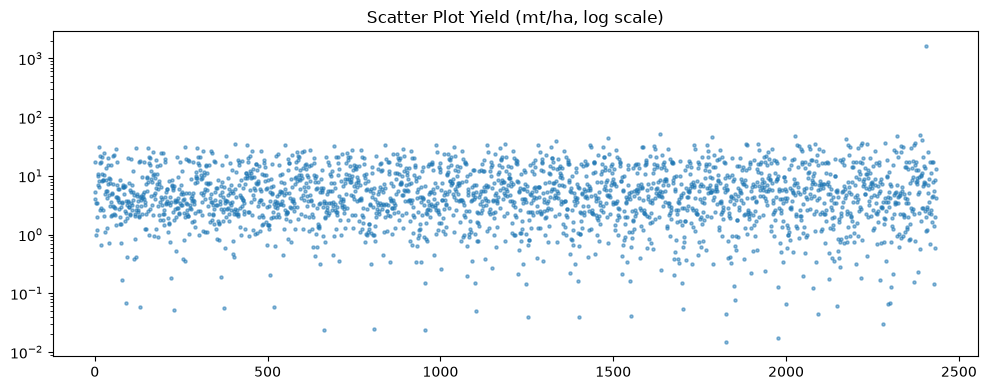

In [9]:
# visually check yield distribution

plt.figure(figsize=(10, 4))
plt.scatter(psa.index, psa['yield'], s=5, alpha=0.5)
plt.yscale('log')
plt.title('Scatter Plot Yield (mt/ha, log scale)')
plt.tight_layout()
plt.show()

# max yield of 1621, a potential error

In [10]:
psa.sort_values('yield', ascending=False).head() # unusual data came from Samar 2026 sem1

,crop,level,region,province,year,period_type,period,area_ha,prod_mt,yield
2406,pineapple,province,region_viii_(eastern_visayas),samar,2026,semester,semester1,4.20,6809.99,1621.426190
1635,pineapple,province,region_v_(bicol_region),camarines_norte,2021,semester,semester1,2341.06,123067.54,52.569152
2387,pineapple,province,region_v_(bicol_region),camarines_norte,2026,semester,semester1,2690.72,135845.21,50.486565
2025,pineapple,province,region_viii_(eastern_visayas),eastern_samar,2023,semester,semester2,29.03,1374.50,47.347571
2321,pineapple,province,negros_island_region_(nir),siquijor,2025,semester,semester2,0.05,2.34,46.800000


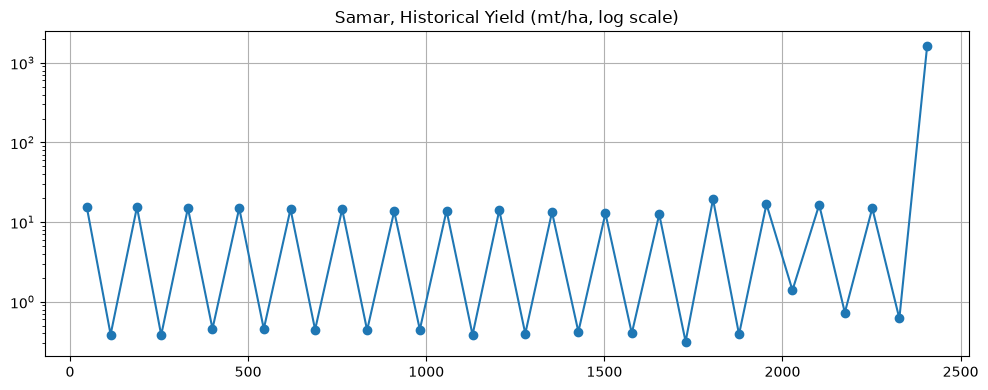

In [11]:
# check and confirm Samar historical yield

psa[psa['province'] == 'samar']['yield'].plot(figsize=(10, 4), marker='o', logy=True, grid=True,
    title='Samar, Historical Yield (mt/ha, log scale)'
    )

plt.tight_layout()
plt.show()

# unusual indeed, likely an error

In [12]:
psa = psa[(psa['yield'] < 100)] # drop implausible yields

psa.describe().round() # better - mean and std, the same

,year,area_ha,prod_mt,yield
count,2434.0,2434.0,2434.0,2434.0
mean,2018.0,840.0,17836.0,7.0
std,5.0,3870.0,96062.0,7.0
min,2010.0,0.0,0.0,0.0
25%,2014.0,8.0,24.0,2.0
50%,2018.0,32.0,103.0,5.0
75%,2022.0,200.0,642.0,9.0
max,2026.0,30507.0,960128.0,53.0


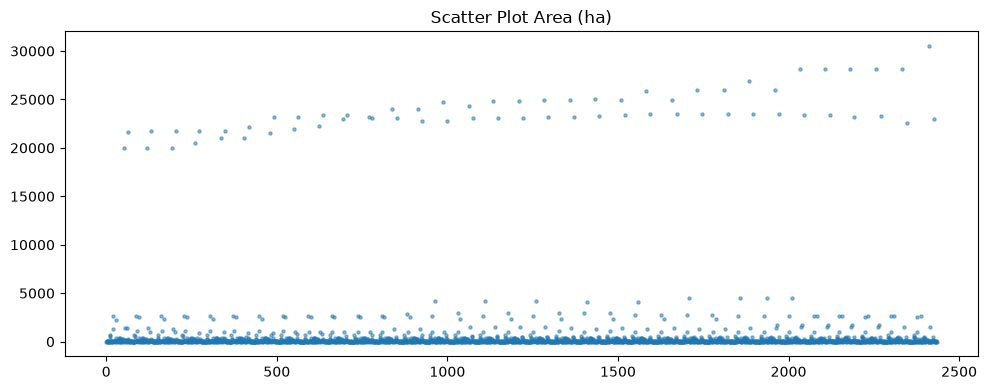

In [13]:
# visually check area distribution

plt.figure(figsize=(10, 4))
plt.scatter(psa.index, psa.area_ha, s=5, alpha=0.5)
plt.title('Scatter Plot Area (ha)')
plt.tight_layout()
plt.show()

# immaterial provinces could be noise, set a minimum

In [14]:
# get share of total to measure materiality

psa['area_share'] = psa['area_ha'] / psa['area_ha'].sum()
psa['prod_share'] = psa['prod_mt'] / psa['prod_mt'].sum()

In [15]:
# get cumulative prod share at given minimum area ha

for a in [10, 20, 50, 100, 200, 300, 400, 500, 750, 1e3, 2e3, 3e3, 4e3, 5e3]:
    segment = psa[psa['area_ha'] < a]
    print(f"{a:,.0f} ha: {(segment.prod_share.sum()):.2%} ({(segment.prod_share.count()):,.0f})")

# check for less than half of one percent

10 ha: 0.04% (747)
20 ha: 0.08% (1,026)
50 ha: 0.26% (1,473)
100 ha: 0.47% (1,717)
200 ha: 0.60% (1,822)
300 ha: 1.18% (1,951)
400 ha: 2.29% (2,090)
500 ha: 3.40% (2,178)
750 ha: 4.27% (2,226)
1,000 ha: 4.62% (2,236)
2,000 ha: 7.34% (2,302)
3,000 ha: 14.01% (2,359)
4,000 ha: 14.01% (2,359)
5,000 ha: 15.33% (2,368)


In [16]:
# give up 1,717 rows but still keep 99.53% of production

psa = psa[(psa['area_ha'] >= 100)]

del psa['area_share']
del psa['prod_share']

psa.describe().round(2)

 # project requirement is >500 rows

,year,area_ha,prod_mt,yield
count,717.00,717.00,717.00,717.00
mean,2017.73,2797.99,60263.41,11.64
std,4.78,6741.64,169710.51,9.24
min,2010.00,100.00,22.66,0.02
25%,2014.00,260.00,1096.96,4.30
50%,2018.00,386.00,4030.17,9.16
75%,2022.00,1036.00,13592.20,16.96
max,2026.00,30506.59,960128.38,52.57


In [17]:
# add feature: yield momentum

psa = psa.sort_values(['region', 'province', 'year', 'period'])
psa['yield_prev1'] = psa.groupby(['region', 'province'])['yield'].shift(1)
psa['yield_prev2'] = psa.groupby(['region', 'province'])['yield'].shift(2)
psa['yield_prev3'] = psa.groupby(['region', 'province'])['yield'].shift(3)
psa['yield_prev4'] = psa.groupby(['region', 'province'])['yield'].shift(4)

#### Observations

Area big jump through 2023 and has been flat to slightly lower since. 
Production and yield are higher in semester 2 in most years; 2020 and 2021 are exceptions. 2026 has semester 1 only.

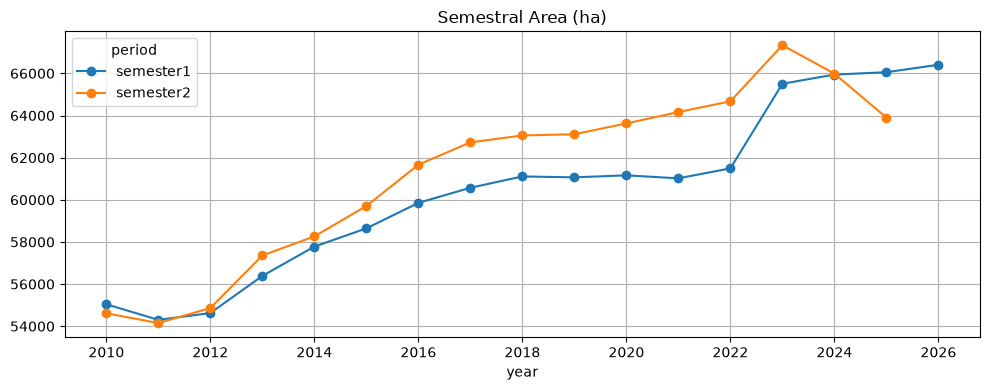

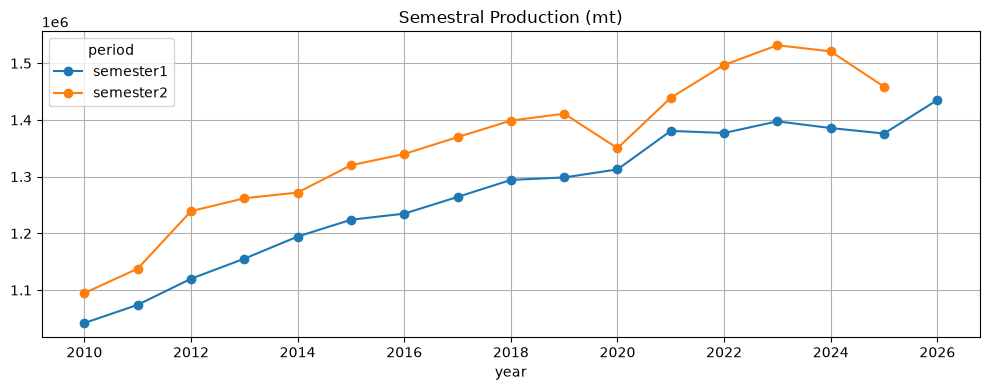

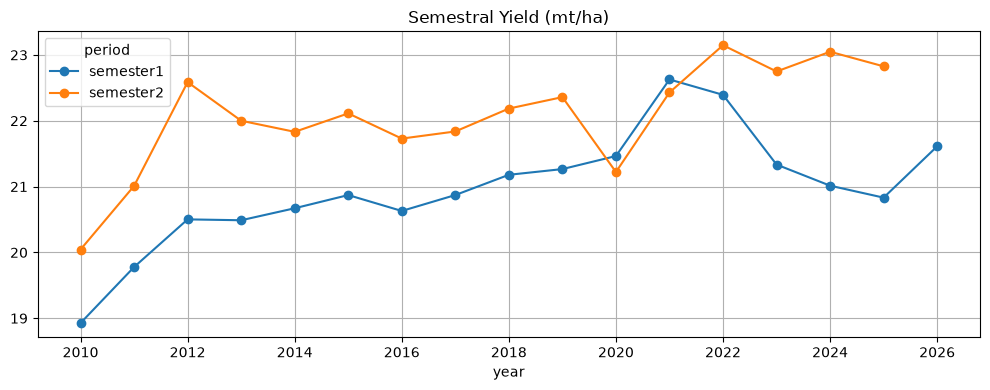

In [18]:
psa_semestral = psa.groupby(['year', 'period'], as_index=False)[['area_ha', 'prod_mt']].sum()
psa_semestral['yield'] = psa_semestral['prod_mt'] / psa_semestral['area_ha']

psa_semestral.pivot(index='year', columns='period', values='area_ha'
    ).plot(figsize=(10, 4), marker='o', grid=True, title='Semestral Area (ha)'
)
plt.tight_layout()

psa_semestral.pivot(index='year', columns='period', values='prod_mt'
    ).plot(figsize=(10, 4), marker='o', grid=True, title='Semestral Production (mt)', 
)
plt.tight_layout()

psa_semestral.pivot(index='year', columns='period', values='yield'
    ).plot(figsize=(10, 4), marker='o', grid=True, title='Semestral Yield (mt/ha)', 
)
plt.tight_layout()


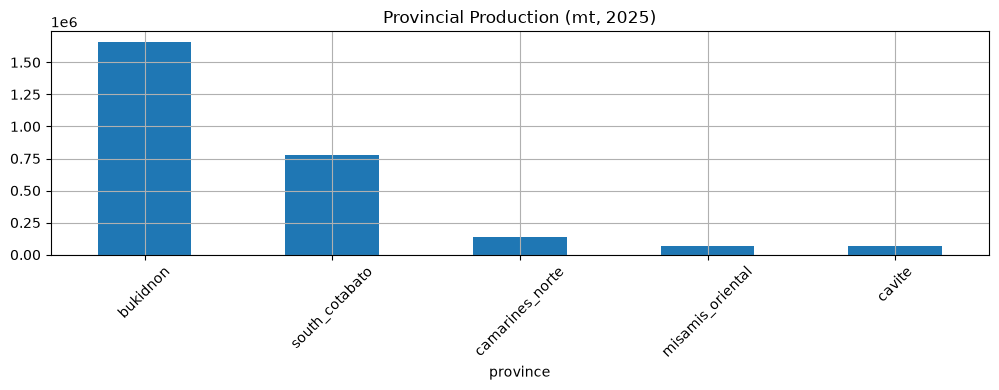

In [19]:
psa_annual_provinces = psa.groupby(['year', 'province'], as_index=False)[['prod_mt']].sum()

psa_semestral_provinces = psa.groupby(['year', 'province', 'period'], as_index=False)[['area_ha', 'prod_mt']].sum()
psa_semestral_provinces['yield'] = psa_semestral_provinces['prod_mt'] / psa_semestral_provinces['area_ha']

psa_annual_provinces[psa_annual_provinces['year'] == 2025].sort_values('prod_mt', ascending=False).head()

# top producing regions last full year cycle
(
    psa_annual_provinces[psa_annual_provinces['year'] == 2025]
    .sort_values('prod_mt', ascending=False).head()
    .set_index('province')['prod_mt']
    .plot(kind='bar', figsize=(10, 4), grid=True,
          title='Provincial Production (mt, 2025)', rot=45)
)
plt.tight_layout()

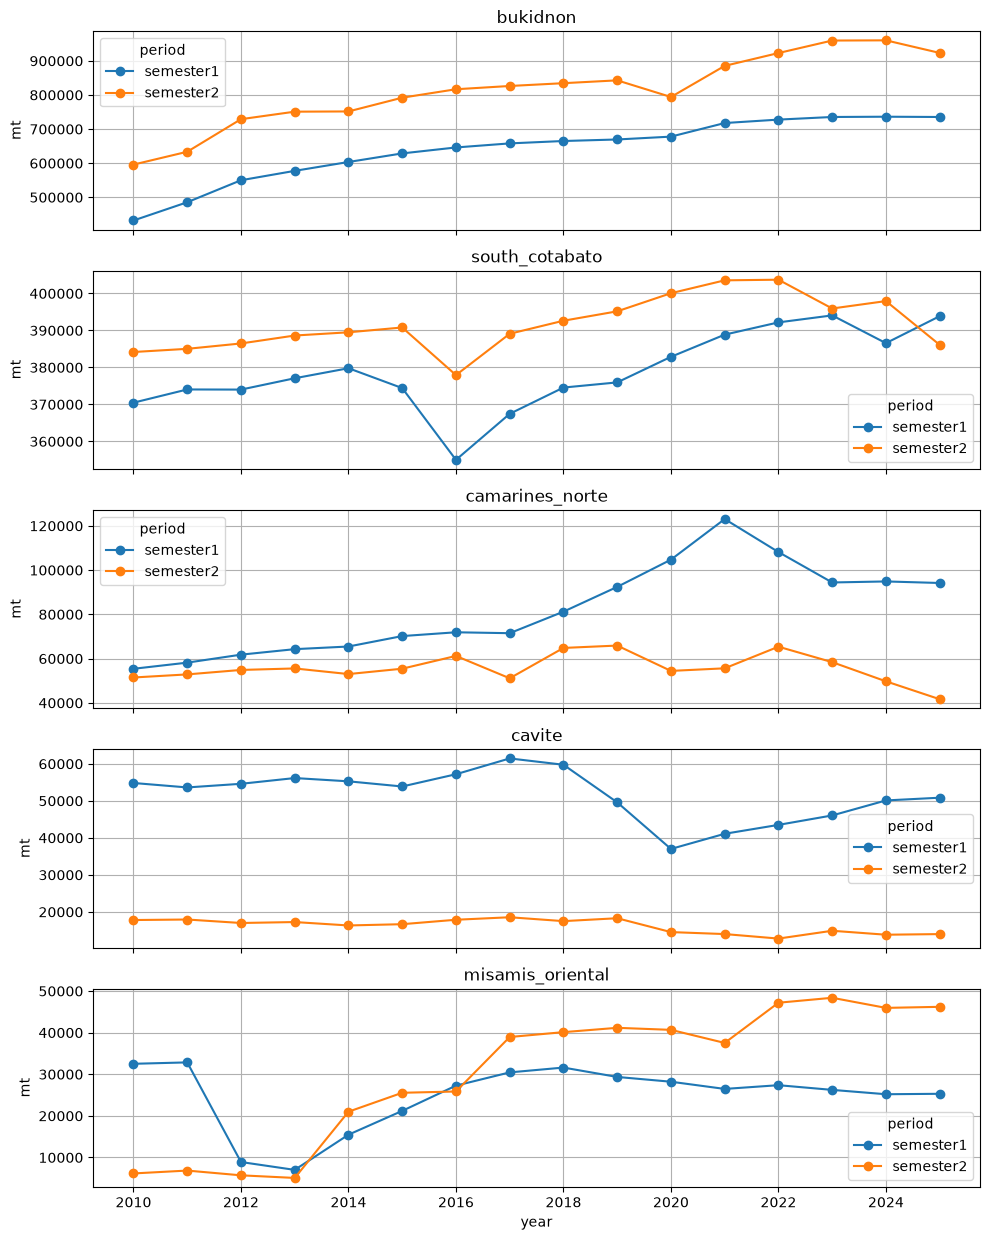

In [20]:
top_provinces = (
    psa_semestral_provinces.groupby('province')['prod_mt'].sum()
    .sort_values(ascending=False).head(5).index
)

fig, axes = plt.subplots(len(top_provinces), 1, figsize=(10, 2.5 * len(top_provinces)), sharex=True)

for ax, prov in zip(axes, top_provinces):
    sub = psa_semestral_provinces[
        (psa_semestral_provinces['province'] == prov) &
        (psa_semestral_provinces.year < 2026)
    ]
    for period, g in sub.groupby('period'):
        g.sort_values('year').plot(x='year', y='prod_mt', ax=ax, marker='o', label=period)
    ax.set_title(prov)
    ax.set_ylabel('mt')
    ax.grid(True)
    ax.legend(title='period')

plt.tight_layout()
plt.show()

# initial impression: top provinces from Mindanao stronger on semester2, Luzon on semester1

### NOAA

In [21]:
noaa_enso_data.head()

,season,year,total,anomaly
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10


In [22]:
# isolate then average, to match psa semestral data
noaa = noaa_enso_data[noaa_enso_data['season'].isin(['JFM', 'AMJ', 'JAS', 'OND'])]
semester = {'JFM': 'semester1', 'AMJ': 'semester1', 'JAS': 'semester2', 'OND': 'semester2'}
noaa['period'] = noaa['season'].map(semester)
noaa = (
    noaa.dropna(subset=['period'])
    .groupby(['year', 'period'], as_index=False)
    .agg(oni_anom=('anomaly', 'mean'), n_seasons=('season', 'size'))
)
noaa.loc[noaa['n_seasons'] < 2, 'oni_anom'] = pd.NA
noaa = noaa.drop(columns='n_seasons')

noaa.tail()

,year,period,oni_anom
149,2024,semester2,-0.165
150,2025,semester1,-0.130
151,2025,semester2,-0.435
152,2026,semester1,0.370
153,2026,semester2,NaN


In [23]:
noaa = noaa.sort_values(['year', 'period']).reset_index(drop=True)
noaa = noaa.rename(columns={'oni_anom': 'oni_anom_sem'})

# check if previous anom can predict yield

noaa['oni_anom_prev1'] = noaa['oni_anom_sem'].shift(1)
noaa['oni_anom_prev2'] = noaa['oni_anom_sem'].shift(2)
noaa['oni_anom_prev3'] = noaa['oni_anom_sem'].shift(3)
noaa['oni_anom_prev4'] = noaa['oni_anom_sem'].shift(4)

noaa = noaa[noaa['year'] >= 2010] # match earliest psa data

# assert noaa['oni_anom_prev'].notna().all()

noaa.tail()

,year,period,oni_anom_sem,oni_anom_prev1,oni_anom_prev2,oni_anom_prev3,oni_anom_prev4
149,2024,semester2,-0.165,0.980,1.575,0.065,-0.800
150,2025,semester1,-0.130,-0.165,0.980,1.575,0.065
151,2025,semester2,-0.435,-0.130,-0.165,0.980,1.575
152,2026,semester1,0.370,-0.435,-0.130,-0.165,0.980
153,2026,semester2,NaN,0.370,-0.435,-0.130,-0.165


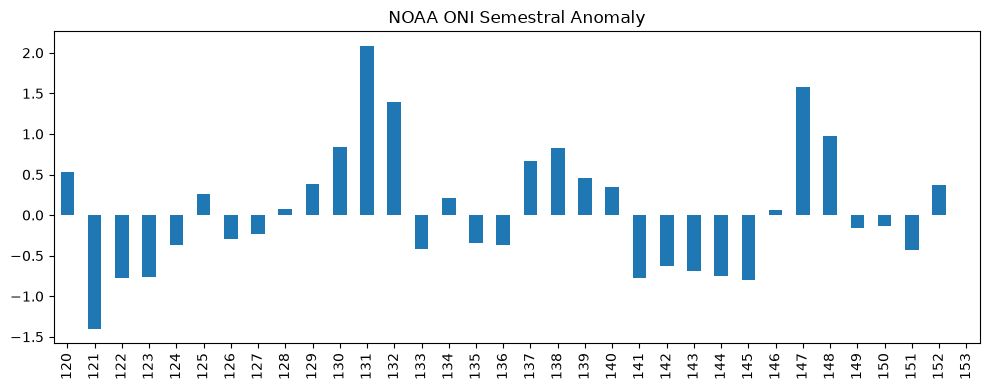

In [24]:
# plot historical semestral anomaly; +/-0.5 is considered significant

noaa.oni_anom_sem.plot(
    kind='bar', figsize=(10, 4),
    title='NOAA ONI Semestral Anomaly'
)

plt.tight_layout()

In [25]:
# merge with psa

psa_noaa = psa.merge(noaa,
    on=['year', 'period'],
    how='left', validate='many_to_one'
)

In [26]:
psa_noaa.info()

<class 'pandas.DataFrame'>
RangeIndex: 717 entries, 0 to 716
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   crop            717 non-null    str    
 1   level           717 non-null    str    
 2   region          717 non-null    str    
 3   province        717 non-null    str    
 4   year            717 non-null    int64  
 5   period_type     717 non-null    str    
 6   period          717 non-null    str    
 7   area_ha         717 non-null    float64
 8   prod_mt         717 non-null    float64
 9   yield           717 non-null    float64
 10  yield_prev1     687 non-null    float64
 11  yield_prev2     658 non-null    float64
 12  yield_prev3     629 non-null    float64
 13  yield_prev4     600 non-null    float64
 14  oni_anom_sem    717 non-null    float64
 15  oni_anom_prev1  717 non-null    float64
 16  oni_anom_prev2  717 non-null    float64
 17  oni_anom_prev3  717 non-null    float64
 18  o

### NASA

In [27]:
nasa = nasa_weather_data
nasa_str_cols = nasa.select_dtypes(include='str')

for c in nasa_str_cols:
    nasa[c] = nasa[c].str.lower().str.replace(' ', '_')

nasa.head()

,region_name,province_name,year,month,parameter,unit,value
0,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,1,allsky_sfc_sw_dwn,mj/m^2/day,16.22
1,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,2,allsky_sfc_sw_dwn,mj/m^2/day,18.53
2,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,3,allsky_sfc_sw_dwn,mj/m^2/day,19.91
3,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,4,allsky_sfc_sw_dwn,mj/m^2/day,19.75
4,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,5,allsky_sfc_sw_dwn,mj/m^2/day,19.57


In [28]:
# dataset has 6 parameters

nasa.parameter.values.value_counts()

# allsky_sfc_sw_dwn: light/energy for photosynthesis; drives biomass and yield.
# prectotcorr: water supply; too little stresses plants, too much causes rot/flooding.
# rh2m: moisture balance; high humidity favors disease, low increases water loss.
# t2m: overall heat; affects growth rate and respiration.
# t2m_max: heat stress/extremes; can reduce fruit set/quality.
# t2m_min: cold stress/flowering triggers; affects development.

allsky_sfc_sw_dwn    19350
prectotcorr          19350
rh2m                 19350
t2m                  19350
t2m_max              19350
t2m_min              19350
Name: count, dtype: int64

In [29]:
# convert monthly to semestral: precipitation as total, others avg

nasa['period'] = nasa['month'].le(6).map({True: 'semester1', False: 'semester2'})
nasa['days_in_month'] = pd.to_datetime(
    nasa[['year', 'month']].assign(day=1)
).dt.days_in_month
nasa['value_total'] = nasa['value'] * nasa['days_in_month']

nasa_sem = (
    nasa.groupby(
        ['region_name', 'province_name', 'year', 'period', 'parameter', 'unit'],
        as_index=False
    )
    .agg(value=('value', 'mean'), value_total=('value_total', 'sum'))
    .rename(columns={'region_name': 'region', 'province_name': 'province'})
)

precip = nasa_sem['parameter'].eq('prectotcorr')
nasa_sem.loc[precip, 'value'] = nasa_sem.loc[precip, 'value_total'].where(
    nasa_sem.loc[precip, 'value'].notna()
)
nasa_sem.loc[precip, 'unit'] = 'mm'
nasa_sem = nasa_sem.drop(columns='value_total')

nasa_sem.head()


,region,province,year,period,parameter,unit,value
0,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,allsky_sfc_sw_dwn,mj/m^2/day,18.646667
1,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,prectotcorr,mm,903.360000
2,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,rh2m,%,81.565000
3,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,t2m,c,27.500000
4,bangsamoro_autonomous_region_in_muslim_mindanao,basilan,2009,semester1,t2m_max,c,29.261667


In [30]:
# pivot one column per parameter

nasa_wide0 = nasa_sem.pivot(
    index=['region', 'province', 'year', 'period'],
    columns='parameter',
    values='value'
).reset_index()

# shift one semester: (Y, S1) <- (Y-1, S2); (Y, S2) <- (Y, S1)

param_cols = [c for c in nasa_wide0.columns
              if c not in ['region', 'province', 'year', 'period']]

# lag features and will let model decide, same as with noaa

def make_lag(df, k):
    out = df.copy()
    # semester index: S1=even, S2=odd within a year
    idx = out['year'].to_numpy() * 2 + out['period'].eq('semester2').to_numpy().astype(int)
    tidx = idx + k
    out['year'] = tidx // 2
    out['period'] = np.where(tidx % 2 == 0, 'semester1', 'semester2')
    suffix = '' if k == 1 else str(k)   # _prev, _prev2, _prev3, _prev4
    rename = {c: f'{c}_prev{suffix}' if suffix else f'{c}_prev' for c in param_cols}
    # simpler/consistent alternative: always f'{c}_prev{k}'
    rename = {c: f'{c}_prev{k}' for c in param_cols}
    out = out.rename(columns=rename)
    return out[['region', 'province', 'year', 'period'] +
               [f'{c}_prev{k}' for c in param_cols]]

# merge data with psa and noaa

psa_noaa_nasa = psa_noaa.copy()
for k in range(1, 5):
    lagged = make_lag(nasa_wide0, k)
    psa_noaa_nasa = psa_noaa_nasa.merge(
        lagged,
        on=['region', 'province', 'year', 'period'],
        how='left', validate='many_to_one'
    )

# assert len(psa_noaa_nasa) == len(psa)
# assert psa_noaa_nasa.filter(like='_prev').notna().all().all()

In [31]:
psa_noaa_nasa.info()

<class 'pandas.DataFrame'>
RangeIndex: 717 entries, 0 to 716
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   crop                     717 non-null    str    
 1   level                    717 non-null    str    
 2   region                   717 non-null    str    
 3   province                 717 non-null    str    
 4   year                     717 non-null    int64  
 5   period_type              717 non-null    str    
 6   period                   717 non-null    str    
 7   area_ha                  717 non-null    float64
 8   prod_mt                  717 non-null    float64
 9   yield                    717 non-null    float64
 10  yield_prev1              687 non-null    float64
 11  yield_prev2              658 non-null    float64
 12  yield_prev3              629 non-null    float64
 13  yield_prev4              600 non-null    float64
 14  oni_anom_sem             717 non-null

<!-- # Data Modelling -->

## Modeling

Time-based split (no leakage): features are lagged and rows are ordered by year before splitting.
- train: year <= 2022
- validate: 2023-2024
- test: >= 2025
Rows with missing `yield_prev2` (first 2 semesters per province) are dropped first.

In [32]:
df = psa_noaa_nasa.copy()

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 717 entries, 0 to 716
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   crop                     717 non-null    str    
 1   level                    717 non-null    str    
 2   region                   717 non-null    str    
 3   province                 717 non-null    str    
 4   year                     717 non-null    int64  
 5   period_type              717 non-null    str    
 6   period                   717 non-null    str    
 7   area_ha                  717 non-null    float64
 8   prod_mt                  717 non-null    float64
 9   yield                    717 non-null    float64
 10  yield_prev1              687 non-null    float64
 11  yield_prev2              658 non-null    float64
 12  yield_prev3              629 non-null    float64
 13  yield_prev4              600 non-null    float64
 14  oni_anom_sem             717 non-null

In [34]:
target = 'yield'

In [35]:
# sorting by time, removing missing yield prev 2

df = df.sort_values(['year', 'period', 'region', 'province']).reset_index(drop=True)
df = df[df['yield_prev2'].notna()].reset_index(drop=True)

In [36]:
# time based

df_train = df[df['year'] <= 2022]
df_val   = df[df['year'].isin([2023, 2024])]
df_test  = df[df['year'] >= 2025] 

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = np.log1p(df_train[target].values)
y_val = np.log1p(df_val[target].values)
y_test = np.log1p(df_test[target].values)

del df_train[target]
del df_val[target]
del df_test[target]

len(df_train), len(df_val), len(df_test)

(513, 80, 65)

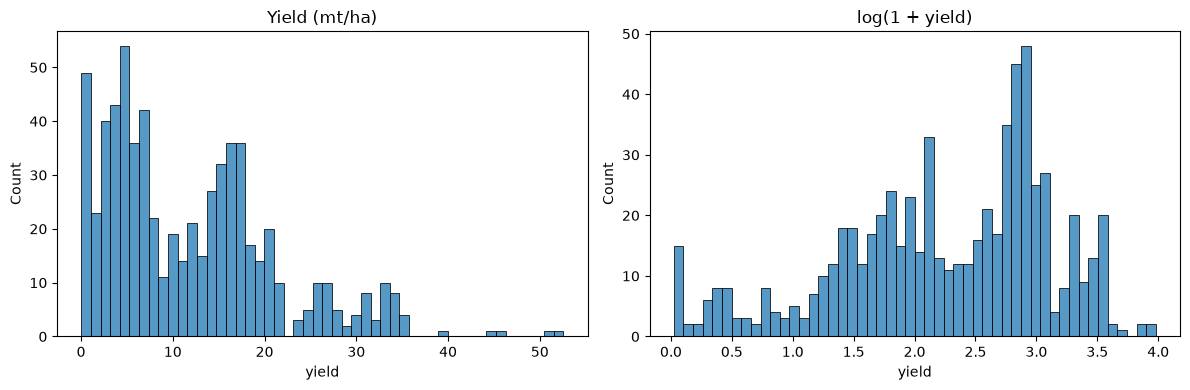

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['yield'], bins=50, ax=ax[0])
ax[0].set_title('Yield (mt/ha)')

sns.histplot(np.log1p(df['yield']), bins=50, ax=ax[1])
ax[1].set_title('log(1 + yield)')

plt.tight_layout()

#### Regression

In [38]:
feats_weather = ['oni_anom', 'allsky_sfc_sw_dwn', 'prectotcorr', 'rh2m', 't2m', 't2m_max', 't2m_min']

In [39]:
# testing each weather lag

for lag in range(1, 5):
    feats = [f'{f}_prev{lag}' for f in feats_weather]
    X_train = df_train[feats]
    X_val = df_val[feats]

    model = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value=0)),
        ('regression', LinearRegression()),
    ])
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    print(f"weather lag {lag} RMSE: {root_mean_squared_error(y_val, y_pred):.3f}")

# best observable lag is 2 (1 year cycle)

weather lag 1 RMSE: 0.794
weather lag 2 RMSE: 0.742
weather lag 3 RMSE: 0.798
weather lag 4 RMSE: 0.721


In [40]:
yield_momo = ['yield_prev1', 'yield_prev2', 'yield_prev3', 'yield_prev4']

In [41]:
for y in yield_momo:
    feats = [y]
    X_train = df_train[feats]
    X_val = df_val[feats]

    model = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value=0)),
        ('regression', LinearRegression()),
    ])
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    print(f"{y}: {root_mean_squared_error(y_val, y_pred):.3f}")

# best observable lag also 2 similar to weather

yield_prev1: 0.813
yield_prev2: 0.533
yield_prev3: 0.842
yield_prev4: 0.584


In [42]:
# final feats: combined lag 2 weather and yield

final_feats = [
    'oni_anom_prev2', 'allsky_sfc_sw_dwn_prev2', 'prectotcorr_prev2',
    'rh2m_prev2', 't2m_prev2', 't2m_max_prev2', 't2m_min_prev2',
    'yield_prev2',
]
X_train = df_train[final_feats]
X_val = df_val[final_feats]

model = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value=0)),
    ('regression', LinearRegression()),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
reg_rmse = root_mean_squared_error(y_val, y_pred)
print(f"regression RMSE: {reg_rmse:.3f}")

regression RMSE: 0.500


### Tree

In [43]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

#### Decision Tree

In [44]:
dt_rmse = []
for d in tqdm(range(1, 11)):
    for s in [1, 5, 10, 15, 20, 50, 100]:
        models = {'decision_tree': DecisionTreeRegressor(
            max_depth=d,
            min_samples_leaf=s,
            random_state=9)
            }

        for name, m in models.items():
            m.fit(X_train.fillna(0), y_train)
            pred = m.predict(X_val.fillna(0))
            rmse = root_mean_squared_error(y_val, pred)
            dt_rmse.append((d, s, rmse))

  0%|          | 0/10 [00:00<?, ?it/s]

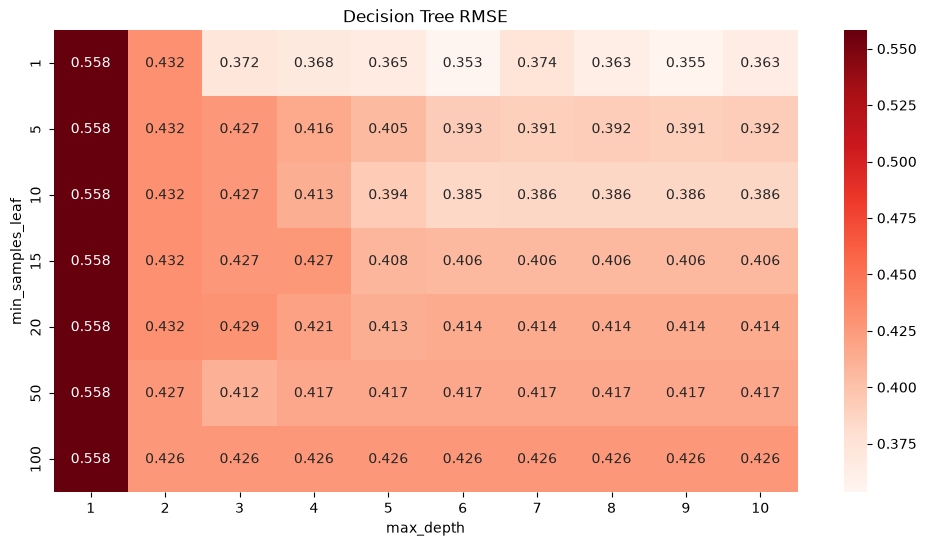

In [45]:
dt_rmse = pd.DataFrame(dt_rmse, columns=['max_depth', 'min_samples_leaf', 'rmse'])
dt_rmse = dt_rmse.pivot(index='min_samples_leaf', columns='max_depth', values='rmse')

plt.figure(figsize=(12, 6))
sns.heatmap(dt_rmse, annot=True, fmt='.3f', cmap='Reds')
plt.title('Decision Tree RMSE')
plt.show()

# low and stable at 6 max depth and 10 min samples

#### Random Forest

In [46]:
rf_rmse = []
for d in tqdm(range(1, 11)):
    for s in [1, 5, 10, 15, 20, 50, 100]:
        models = {'random_forest': RandomForestRegressor(
            n_estimators=200,
            max_depth=d, 
            min_samples_leaf=s,
            random_state=9, 
            n_jobs=-1)
            }

        for name, m in models.items():
            m.fit(X_train.fillna(0), y_train)
            pred = m.predict(X_val.fillna(0))
            rmse = root_mean_squared_error(y_val, pred)
            rf_rmse.append((d, s, rmse))

  0%|          | 0/10 [00:00<?, ?it/s]

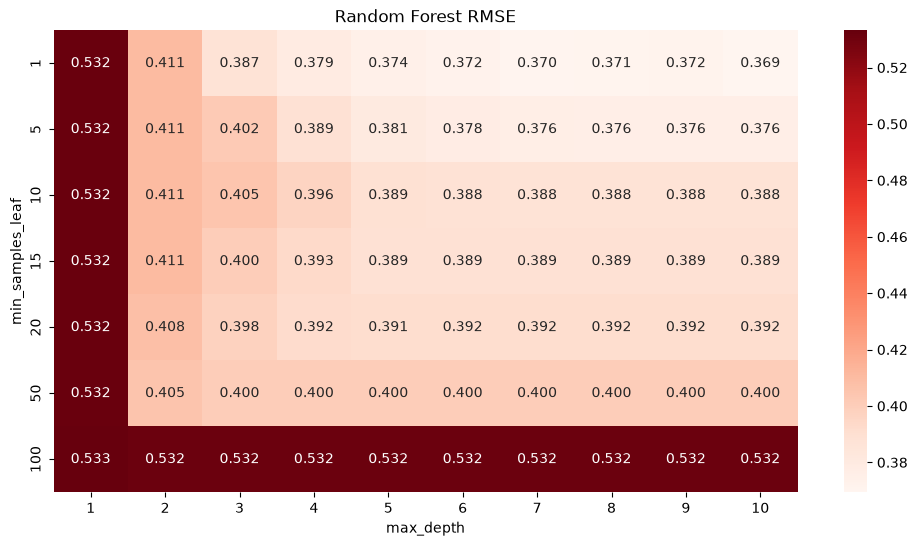

In [47]:
rf_rmse = pd.DataFrame(rf_rmse, columns=['max_depth', 'min_samples_leaf', 'rmse'])
rf_rmse = rf_rmse.pivot(index='min_samples_leaf', columns='max_depth', values='rmse')

plt.figure(figsize=(12, 6))
sns.heatmap(rf_rmse, annot=True, fmt='.3f', cmap='Reds')
plt.title('Random Forest RMSE')
plt.show()

# the same as decision tree: 5 max depth, 15 min samples

In [48]:
rf_rmse_n = []
for n in tqdm(range(10, 301, 10)):
    models = {'random_forest': RandomForestRegressor(
        n_estimators=n,
        max_depth=5,         # from prior cell         
        min_samples_leaf=15, # from prior cell         
        random_state=9, 
        n_jobs=-1)
        }

    for name, m in models.items():
        m.fit(X_train.fillna(0), y_train)
        pred = m.predict(X_val.fillna(0))
        rmse = root_mean_squared_error(y_val, pred)
        rf_rmse_n.append((n, rmse))

  0%|          | 0/30 [00:00<?, ?it/s]

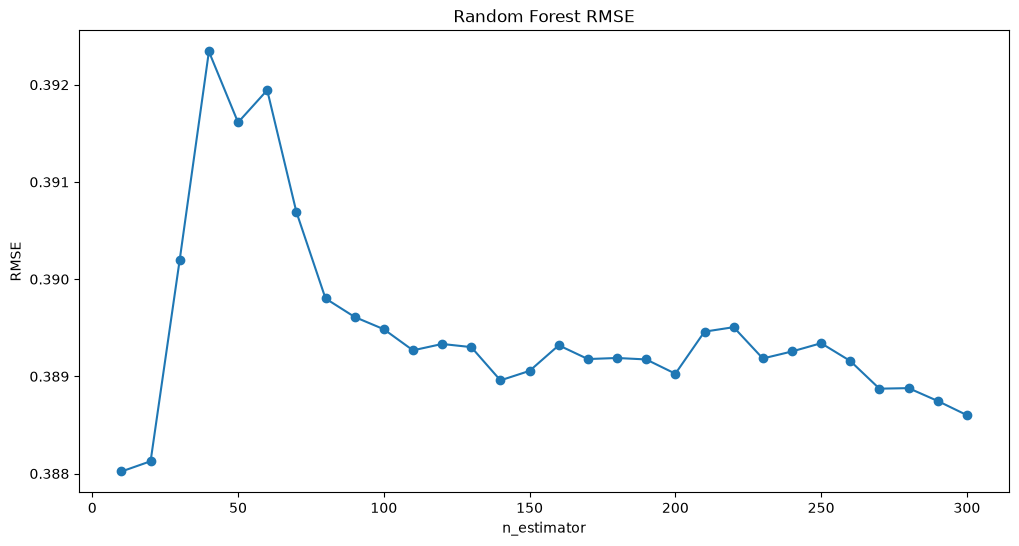

In [49]:
rf_rmse_n = pd.DataFrame(rf_rmse_n, columns=['n', 'rmse'])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(rf_rmse_n.n, rf_rmse_n.rmse, marker='o')
ax.set_title('Random Forest RMSE')
ax.set_xlabel('n_estimator')
ax.set_ylabel('RMSE')
plt.show()

In [50]:
print(rf_rmse_n.sort_values('rmse', ascending=True).head().reset_index(drop=True))
print(f"{'-' * 16}")
print(f"min - max:  {abs(rf_rmse_n.rmse.max() - rf_rmse_n.rmse.min()):.3f}")

# low at 300 but practically immaterial impact

     n      rmse
0   10  0.388021
1   20  0.388127
2  300  0.388601
3  290  0.388747
4  270  0.388873
----------------
min - max:  0.004


#### XGBoost


In [51]:
xgb_rmse = []
for d in tqdm(range(1, 11)):
    for s in [1, 5, 10, 15, 20, 50, 100]:
        models = {'xgboost': xgb.XGBRegressor(
            n_estimators=300, 
            max_depth=d, 
            min_child_weight=s,
            learning_rate=0.05, 
            random_state=9)
            }

        for name, m in models.items():
            m.fit(X_train.fillna(0), y_train)
            pred = m.predict(X_val.fillna(0))
            rmse = root_mean_squared_error(y_val, pred)
            xgb_rmse.append((d, s, rmse))

  0%|          | 0/10 [00:00<?, ?it/s]

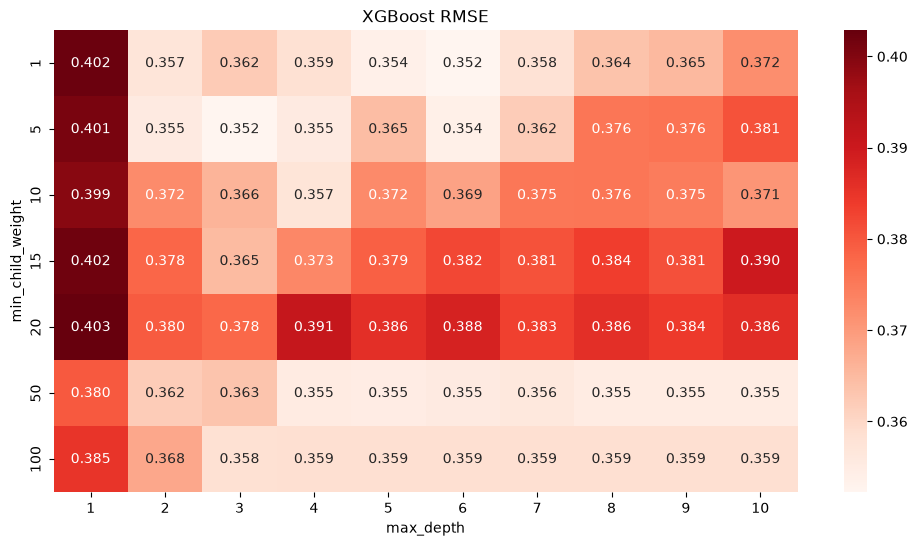

In [52]:
xgb_rmse = pd.DataFrame(xgb_rmse, columns=['max_depth', 'min_child_weight', 'rmse'])
xgb_rmse = xgb_rmse.pivot(index='min_child_weight', columns='max_depth', values='rmse')

plt.figure(figsize=(12, 6))
sns.heatmap(xgb_rmse, annot=True, fmt='.3f', cmap='Reds')
plt.title('XGBoost RMSE')
plt.show()

# min child 50, max depth 4

In [53]:
xg_rmse_n = []
for n in tqdm(range(10, 301, 10)):
    models = {'xgboost': xgb.XGBRegressor(
        n_estimators=n, 
        max_depth=4,         # from prior cell
        min_child_weight=50, # from prior cell
        learning_rate=0.05, 
        random_state=9)
        }

    for name, m in models.items():
        m.fit(X_train.fillna(0), y_train)
        pred = m.predict(X_val.fillna(0))
        rmse = root_mean_squared_error(y_val, pred)
        xg_rmse_n.append((n, rmse))

  0%|          | 0/30 [00:00<?, ?it/s]

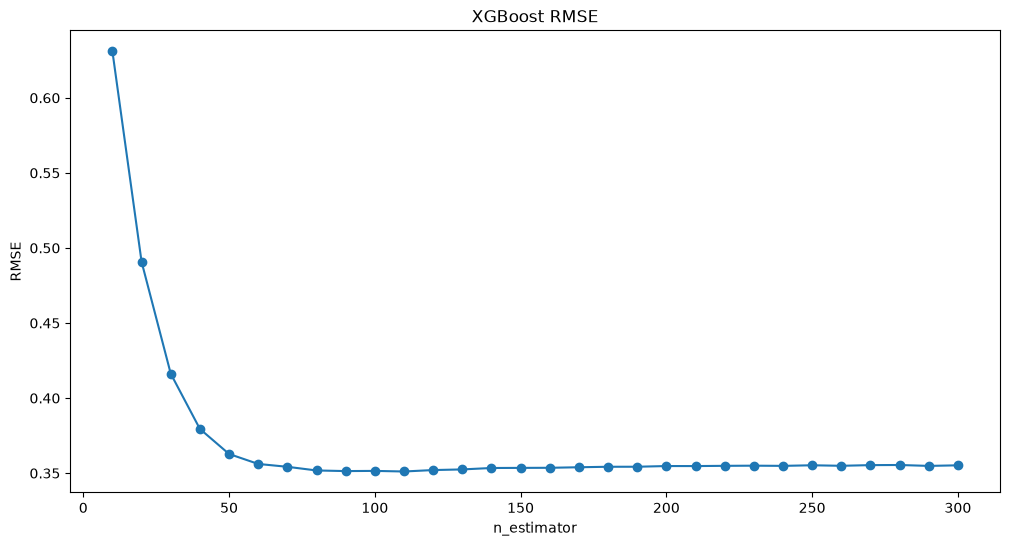

In [54]:
xg_rmse_n = pd.DataFrame(xg_rmse_n, columns=['n', 'rmse'])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(xg_rmse_n.n, xg_rmse_n.rmse, marker='o')
ax.set_title('XGBoost RMSE')
ax.set_xlabel('n_estimator')
ax.set_ylabel('RMSE')
plt.show()

In [55]:
print(xg_rmse_n.sort_values('rmse', ascending=True).head().reset_index(drop=True))
print(f"{'-' * 16}")
print(f"min - max:  {abs(xg_rmse_n.rmse.max() - xg_rmse_n.rmse.min()):.3f}")

# 110 quite significant unlike rf estimators

     n      rmse
0  110  0.351110
1   90  0.351387
2  100  0.351510
3   80  0.351803
4  120  0.352064
----------------
min - max:  0.280


#### Baseline

In [56]:
# naive baseline: predict last semester's yield
baseline_pred = df_test['yield_prev2'].values
print(f"naive yield_prev2 RMSE (log1p): {root_mean_squared_error(y_test, np.log1p(baseline_pred)):.3f}")


naive yield_prev2 RMSE (log1p): 0.379


## Evaluation

In [57]:
X_full_train = pd.concat([X_train, X_val]).reset_index(drop=True)
y_full_train = np.concatenate([y_train, y_val])
X_test = df_test[list(X_full_train.columns)]

In [58]:
# dt: 6 max depth, 10 min sample size
# rt: 5 max depth, 15 min sample size, 300 n_estimators
# xg: 4 max depth, 50 min child weigh, 110 n_estimators

In [59]:
# train val RSME across models

print(f"regression: {round(reg_rmse, 2)}")

models = {
    'decision_tree': DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=9),
    'random_forest': RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=15, random_state=9, n_jobs=-1),
    'xgboost': xgb.XGBRegressor(n_estimators=110, max_depth=4, min_child_weight=50, learning_rate=0.05, random_state=9),
}

for name, m in models.items():
    m.fit(X_train.fillna(0), y_train)
    pred = m.predict(X_val.fillna(0))
    print(f"{name}: {root_mean_squared_error(y_val, pred):.3f}")

# best model xgboost

regression: 0.5
decision_tree: 0.385


random_forest: 0.389
xgboost: 0.351


In [60]:
# full train and test xgboost

models = {
    'xgboost': xgb.XGBRegressor(n_estimators=110, max_depth=4, min_child_weight=50, learning_rate=0.05, random_state=9),
}

for name, m in models.items():
    m.fit(X_full_train.fillna(0), y_full_train)
    pred = m.predict(X_test.fillna(0))
    print(f"{name}: {root_mean_squared_error(y_test, pred):.3f}")

# best feature yield_prev2

xgboost: 0.399

In [61]:
# back-transform: report RMSE in original units (mt/ha)

y_pred_log = models['xgboost'].predict(X_test.fillna(0))
y_true_mt = np.expm1(y_test)
y_pred_mt = np.expm1(y_pred_log)
print(f"rmse (log1p): {root_mean_squared_error(y_test, y_pred_log):.3f}")
print(f"rmse (mt/ha): {root_mean_squared_error(y_true_mt, y_pred_mt):.2f}")


rmse (log1p): 0.399
rmse (mt/ha): 4.18


#### Feature Importance

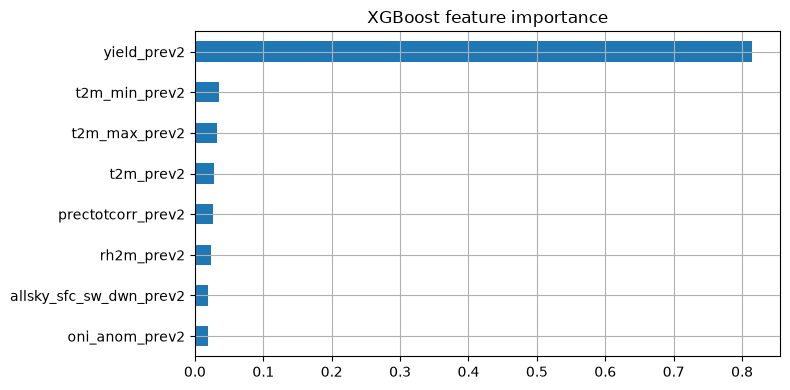

yield_prev2                0.815
t2m_min_prev2              0.036
t2m_max_prev2              0.032
t2m_prev2                  0.028
prectotcorr_prev2          0.026
rh2m_prev2                 0.024
oni_anom_prev2             0.019
allsky_sfc_sw_dwn_prev2    0.019
dtype: float32


In [62]:
imp_xgb = pd.Series(models['xgboost'].feature_importances_, index=X_test.columns).sort_values()
imp_xgb.plot(kind='barh', figsize=(8, 4), grid=True, title='XGBoost feature importance')
plt.tight_layout()
plt.show()
print(imp_xgb.round(3).sort_values(ascending=False))


#### Early Warning (test period)
Features are lagged 2 semesters, so this alert exists roughly 12 months before harvest. Flag a province when predicted yield falls >=10% below its last observed yield (yield_prev2).

In [63]:
# early warning: which provinces are at risk next semester?
y_pred_log = models['xgboost'].predict(X_test.fillna(0))

ew = df_test[['region', 'province', 'year', 'period', 'area_ha']].copy().reset_index(drop=True)
ew['yield_prev2'] = df_test['yield_prev2'].values
ew['yield_pred'] = np.expm1(y_pred_log)
ew['pct_change'] = (ew['yield_pred'] / ew['yield_prev2'] - 1) * 100
ew['alert'] = ew['pct_change'] <= -10
ew['mt_at_risk'] = (ew['area_ha'] * (ew['yield_prev2'] - ew['yield_pred']).clip(lower=0)).round(1)
ew = ew.sort_values('mt_at_risk', ascending=False).reset_index(drop=True)

print(f"alerts: {int(ew['alert'].sum())} of {len(ew)} provinces")
display(ew.loc[ew['alert'], ['region','province','year','period','yield_prev2','yield_pred','pct_change','mt_at_risk']]
       .sort_values('mt_at_risk', ascending=False).round(2).reset_index(drop=True))


alerts: 13 of 65 provinces


,region,province,year,period,yield_prev2,yield_pred,pct_change,mt_at_risk
0,region_v_(bicol_region),camarines_norte,2025,semester1,35.26,28.719999,-18.54,17589.3
1,region_v_(bicol_region),camarines_norte,2026,semester1,35.00,29.740000,-15.04,14166.1
2,region_x_(northern_mindanao),misamis_oriental,2026,semester1,16.87,14.880000,-11.81,2989.1
3,region_iv-a_(calabarzon),cavite,2025,semester2,5.22,4.670000,-10.48,1454.4
4,region_ii_(cagayan_valley),nueva_vizcaya,2025,semester1,31.87,28.510000,-10.54,1432.7
5,region_viii_(eastern_visayas),leyte,2025,semester1,7.22,6.320000,-12.42,251.2
6,region_iv-a_(calabarzon),quezon,2025,semester1,7.14,6.390000,-10.54,188.1
7,region_viii_(eastern_visayas),leyte,2025,semester2,4.64,4.140000,-10.77,139.8
8,region_v_(bicol_region),camarines_sur,2025,semester1,1.15,0.770000,-32.56,118.2
9,region_viii_(eastern_visayas),samar,2025,semester2,0.73,0.540000,-25.66,78.9


#### Cost of Late Intervention
Value of production at risk in alerted provinces (exposure, not proven savings). Assumes a blended farmgate price of PHP 15/kg (PSA, ~2024-25).

In [64]:
FARMGATE_PHP_PER_KG = 15.0
ew_alerts = ew[ew['alert']].copy()
ew_alerts['php_at_risk'] = ew_alerts['mt_at_risk'] * 1000 * FARMGATE_PHP_PER_KG
tot_mt = ew_alerts['mt_at_risk'].sum()
tot_php = ew_alerts['php_at_risk'].sum()
print(f"production at risk: {tot_mt:,.0f} mt  (~PHP {tot_php/1e6:,.1f} M)")
display(ew_alerts[['province','year','period','mt_at_risk','php_at_risk']]
       .sort_values('php_at_risk', ascending=False).round(0).head(10).reset_index(drop=True))


production at risk: 38,598 mt  (~PHP 579.0 M)


,province,year,period,mt_at_risk,php_at_risk
0,camarines_norte,2025,semester1,17589.0,263839500.0
1,camarines_norte,2026,semester1,14166.0,212491500.0
2,misamis_oriental,2026,semester1,2989.0,44836500.0
3,cavite,2025,semester2,1454.0,21816000.0
4,nueva_vizcaya,2025,semester1,1433.0,21490500.0
5,leyte,2025,semester1,251.0,3768000.0
6,quezon,2025,semester1,188.0,2821500.0
7,leyte,2025,semester2,140.0,2097000.0
8,camarines_sur,2025,semester1,118.0,1773000.0
9,samar,2025,semester2,79.0,1183500.0
